# Octobre Rose · Diagnostic précoce et survie au cancer du sein

**Cas d'étude data** — Matar Ndoye Keita, étudiant MBA Data & IA (ISM Dakar)

## Contexte

Une ONG (fictive) de lutte contre le cancer du sein prépare sa campagne Octobre Rose. Elle doit décider **où concentrer ses moyens** : sensibilisation au dépistage, accompagnement des patientes, plaidoyer pour l'accès aux examens.

Elle pose trois questions :

1. **Combien le moment du diagnostic pèse-t-il sur la survie ?** (stade, taille de la tumeur, ganglions atteints)
2. **Quels profils de patientes ont le pronostic le plus défavorable ?** (biologie de la tumeur, âge, situation familiale)
3. **Quels messages et quelles cibles prioriser ?**

## Données

Jeu de données [*SEER Breast Cancer*](https://www.kaggle.com/datasets/reihanenamdari/breast-cancer) (Kaggle), extrait du programme SEER du National Cancer Institute (États-Unis) : **4 024 femmes** diagnostiquées entre 2006 et 2010 d'un carcinome canalaire ou lobulaire infiltrant, toutes avec au moins un ganglion atteint (stades IIA à IIIC).

> ⚠️ Ce sont des données américaines. Elles servent ici à quantifier un mécanisme (diagnostic tardif → survie plus faible), pas à décrire la situation au Sénégal.

## 1. Import des bibliothèques

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

# Charte graphique Octobre Rose
ROSE, ROSE_CLAIR, NAVY, GRIS = "#D6336C", "#F4A6C1", "#1B2A4A", "#A3ABBA"
RAMPE = ["#F2A0BE", "#EB6F9C", "#DB4680", "#B52A61", "#7E1743"]  # du plus précoce au plus tardif
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#C8CDD6", "axes.labelcolor": NAVY, "xtick.color": NAVY,
                     "ytick.color": NAVY, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.titlecolor": NAVY, "font.size": 11})

## 2. Chargement et premier aperçu

In [2]:
df = pd.read_csv("data/Breast_Cancer.csv")
print(f"{df.shape[0]} lignes × {df.shape[1]} colonnes")
df.head()

4024 lignes × 16 colonnes


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     4024 non-null   int64
 1   Race                    4024 non-null   str  
 2   Marital Status          4024 non-null   str  
 3   T Stage                 4024 non-null   str  
 4   N Stage                 4024 non-null   str  
 5   6th Stage               4024 non-null   str  
 6   differentiate           4024 non-null   str  
 7   Grade                   4024 non-null   str  
 8   A Stage                 4024 non-null   str  
 9   Tumor Size              4024 non-null   int64
 10  Estrogen Status         4024 non-null   str  
 11  Progesterone Status     4024 non-null   str  
 12  Regional Node Examined  4024 non-null   int64
 13  Reginol Node Positive   4024 non-null   int64
 14  Survival Months         4024 non-null   int64
 15  Status                  4024 non

## 3. Nettoyage et qualité des données

Points relevés à l'exploration :
- des espaces parasites dans certains noms de colonnes (`"T Stage "`) et certaines valeurs (`"Single "`) ;
- une coquille dans un nom de colonne (`Reginol Node Positive`) ;
- un grade codé en texte (`" anaplastic; Grade IV"`) au lieu de `4`.

In [4]:
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"Reginol Node Positive": "Regional Node Positive", "differentiate": "Differentiate"})
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].str.strip()
df["Grade"] = df["Grade"].replace({"anaplastic; Grade IV": "4"})

print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Doublons exacts    :", int(df.duplicated().sum()))

Valeurs manquantes : 0
Doublons exacts    : 1


In [5]:
# Une ligne strictement identique : on la retire
df = df.drop_duplicates().reset_index(drop=True)

# Contrôles de cohérence métier
incoh_ganglions = (df["Regional Node Positive"] > df["Regional Node Examined"]).sum()
incoh_t3 = df[(df["T Stage"] == "T3") & (df["Tumor Size"] <= 50)]
print("Ganglions positifs > ganglions examinés :", incoh_ganglions)
print("Tumeurs classées T3 (> 50 mm) avec une taille ≤ 50 mm :", len(incoh_t3))
incoh_t3[["Tumor Size", "T Stage", "N Stage", "6th Stage"]]

Ganglions positifs > ganglions examinés : 0
Tumeurs classées T3 (> 50 mm) avec une taille ≤ 50 mm : 7


,Tumor Size,T Stage,N Stage,6th Stage
227,50,T3,N1,IIIA
1189,6,T3,N2,IIIA
1828,50,T3,N2,IIIA
2287,4,T3,N1,IIIA
2892,50,T3,N2,IIIA
2948,40,T3,N1,IIIA
3783,45,T3,N1,IIIA


**Qualité :** aucune valeur manquante, un doublon retiré, et **7 tumeurs classées T3 alors que leur taille est ≤ 50 mm** (dont 4 nettement incohérentes : 4, 6, 40 et 45 mm). On les conserve en les signalant : l'effet sur les résultats est négligeable, mais dans un vrai registre ce serait à corriger à la source.

In [6]:
# Variables d'analyse
df["deces"] = (df["Status"] == "Dead").astype(int)
df["mois"] = df["Survival Months"]
df["Âge"] = pd.cut(df["Age"], [29, 39, 49, 59, 69], labels=["30-39", "40-49", "50-59", "60-69"])
df["Taille"] = pd.cut(df["Tumor Size"], [0, 20, 50, 500], labels=["≤ 20 mm", "21-50 mm", "> 50 mm"])
df["Ganglions"] = pd.cut(df["Regional Node Positive"], [0, 3, 9, 100], labels=["1-3", "4-9", "10 et +"])
df["Hormones"] = np.where((df["Estrogen Status"] == "Negative") & (df["Progesterone Status"] == "Negative"),
                          "RE- et RP-", "Au moins un récepteur +")
df["Situation"] = np.where(df["Marital Status"] == "Married", "Mariée", "Non mariée")
N = len(df)
print(f"{N} patientes · {df['deces'].sum()} décès ({df['deces'].mean():.1%}) · suivi médian {df['mois'].median():.0f} mois")

4023 patientes · 616 décès (15.3%) · suivi médian 73 mois


## 4. Profil des patientes

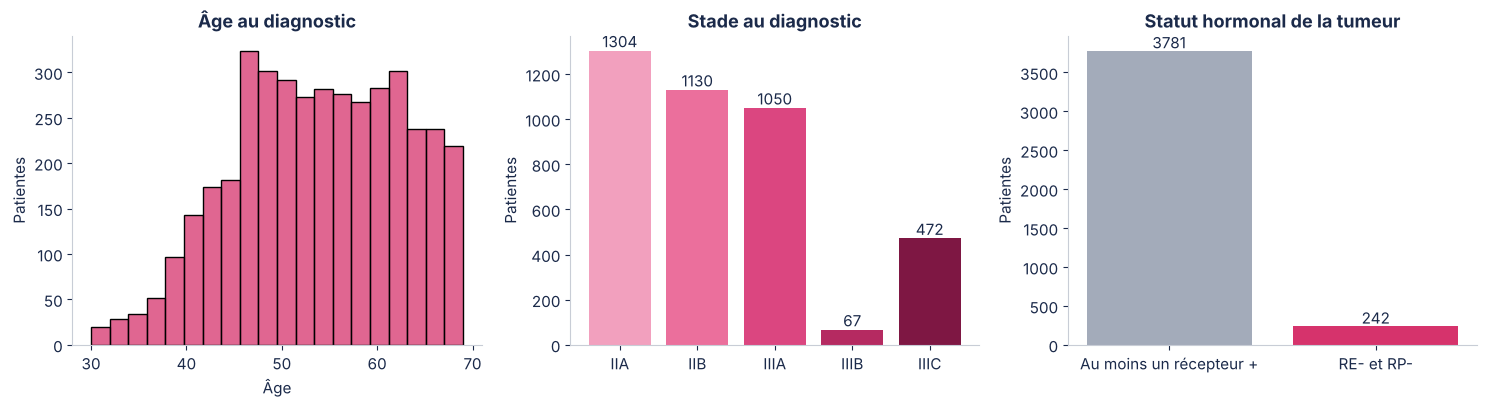

Âge médian : 54 ans · stade III : 39.5% · taille médiane : 25 mm


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(df["Age"], bins=20, color=ROSE, ax=axes[0])
axes[0].set_title("Âge au diagnostic"); axes[0].set_xlabel("Âge"); axes[0].set_ylabel("Patientes")

ordre = ["IIA", "IIB", "IIIA", "IIIB", "IIIC"]
cnt = df["6th Stage"].value_counts().reindex(ordre)
axes[1].bar(cnt.index, cnt.values, color=RAMPE)
axes[1].set_title("Stade au diagnostic"); axes[1].set_ylabel("Patientes")
for i, v in enumerate(cnt.values):
    axes[1].text(i, v + 15, f"{v}", ha="center", color=NAVY)

h = df["Hormones"].value_counts()
axes[2].bar(h.index, h.values, color=[GRIS, ROSE])
axes[2].set_title("Statut hormonal de la tumeur"); axes[2].set_ylabel("Patientes")
for i, v in enumerate(h.values):
    axes[2].text(i, v + 30, f"{v}", ha="center", color=NAVY)
plt.tight_layout(); plt.show()

print(f"Âge médian : {df['Age'].median():.0f} ans · stade III : {df['6th Stage'].str.startswith('III').mean():.1%} · taille médiane : {df['Tumor Size'].median():.0f} mm")

Les patientes ont entre 30 et 69 ans (médiane 54 ans). **Près de 4 sur 10 sont diagnostiquées au stade III**, c'est-à-dire avec une maladie déjà localement avancée.

## 5. Mortalité brute par facteur

Premier regard : la part de décès observée dans chaque groupe. Attention, le suivi varie d'une patiente à l'autre (1 à 107 mois) : ce taux brut est indicatif, la section suivante corrige ce biais avec l'analyse de survie.

In [8]:
def mortalite(col):
    g = df.groupby(col, observed=True)["deces"].agg(patientes="size", deces="sum", taux="mean")
    g["taux"] = (g["taux"] * 100).round(1)
    return g

for col in ["6th Stage", "T Stage", "N Stage", "Taille", "Ganglions", "Grade", "Hormones", "Âge", "Situation"]:
    display(mortalite(col).rename(columns={"taux": "taux de décès (%)"}))

,patientes,deces,taux de décès (%)
6th Stage,,,
IIA,1304,96,7.4
IIB,1130,135,11.9
IIIA,1050,184,17.5
IIIB,67,20,29.9
IIIC,472,181,38.3


,patientes,deces,taux de décès (%)
T Stage,,,
T1,1602,157,9.8
T2,1786,303,17.0
T3,533,116,21.8
T4,102,40,39.2


,patientes,deces,taux de décès (%)
N Stage,,,
N1,2731,270,9.9
N2,820,165,20.1
N3,472,181,38.3


,patientes,deces,taux de décès (%)
Taille,,,
≤ 20 mm,1619,164,10.1
21-50 mm,1824,317,17.4
> 50 mm,580,135,23.3


,patientes,deces,taux de décès (%)
Ganglions,,,
1-3,2681,265,9.9
4-9,881,178,20.2
10 et +,461,173,37.5


,patientes,deces,taux de décès (%)
Grade,,,
1,543,39,7.2
2,2350,305,13.0
3,1111,263,23.7
4,19,9,47.4


,patientes,deces,taux de décès (%)
Hormones,,,
Au moins un récepteur +,3781,514,13.6
RE- et RP-,242,102,42.1


,patientes,deces,taux de décès (%)
Âge,,,
30-39,230,47,20.4
40-49,1124,136,12.1
50-59,1390,189,13.6
60-69,1279,244,19.1


,patientes,deces,taux de décès (%)
Situation,,,
Mariée,2642,358,13.6
Non mariée,1381,258,18.7


## 6. Survie à 5 ans selon le stade au diagnostic (Kaplan-Meier)

L'estimateur de Kaplan-Meier tient compte des patientes encore en vie dont le suivi est plus court que 5 ans (données censurées). Le test du log-rank vérifie si les courbes diffèrent significativement.

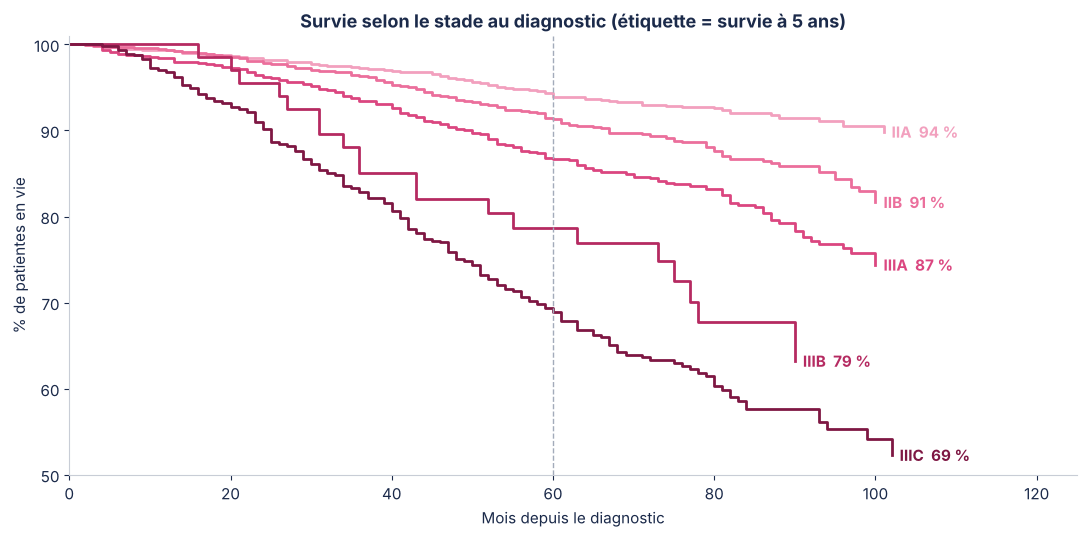

In [9]:
def survie(sub, t=60):
    sf = SurvfuncRight(sub["mois"], sub["deces"])
    i = np.searchsorted(sf.surv_times, t, side="right") - 1
    return sf.surv_prob[i] if i >= 0 else 1.0

def courbes(col, ordre, couleurs, titre, ax):
    for niveau, c in zip(ordre, couleurs):
        sub = df[df[col] == niveau]
        sf = SurvfuncRight(sub["mois"], sub["deces"])
        x = np.r_[0, sf.surv_times]; y = np.r_[1, sf.surv_prob]
        ax.step(x, y * 100, where="post", color=c, lw=2)
        ax.text(x[-1] + 1, y[-1] * 100, f"{niveau}  {survie(sub) * 100:.0f} %", color=c, va="center", fontweight="bold")
    ax.axvline(60, color=GRIS, ls="--", lw=1)
    ax.set_xlim(0, 125); ax.set_ylim(50, 101)
    ax.set_xlabel("Mois depuis le diagnostic"); ax.set_ylabel("% de patientes en vie")
    ax.set_title(titre)

fig, ax = plt.subplots(figsize=(11, 5.5))
courbes("6th Stage", ["IIA", "IIB", "IIIA", "IIIB", "IIIC"], RAMPE, "Survie selon le stade au diagnostic (étiquette = survie à 5 ans)", ax)
plt.tight_layout(); plt.show()

In [10]:
def tableau_survie(col, ordre):
    rows = []
    for niveau in ordre:
        sub = df[df[col] == niveau]
        rows.append({col: niveau, "patientes": len(sub), "survie à 5 ans (%)": round(survie(sub) * 100, 1)})
    stat, p = survdiff(df["mois"], df["deces"], df[col].astype(str))
    p_txt = "< 1e-16" if p < 1e-16 else f"= {p:.1e}"
    print(f"Log-rank {col} : χ² = {stat:.1f}, p {p_txt}")
    return pd.DataFrame(rows).set_index(col)

print(f"Survie globale à 5 ans : {survie(df):.1%}")
tableau_survie("6th Stage", ["IIA", "IIB", "IIIA", "IIIB", "IIIC"])

Survie globale à 5 ans : 88.1%
Log-rank 6th Stage : χ² = 309.9, p < 1e-16


,patientes,survie à 5 ans (%)
6th Stage,,
IIA,1304,93.9
IIB,1130,91.3
IIIA,1050,86.7
IIIB,67,78.7
IIIC,472,68.9


**Résultat clé :** une patiente diagnostiquée au **stade IIA** a **94 %** de chances d'être en vie à 5 ans ; au **stade IIIC**, **69 %**. Environ **25 points de survie** séparent un diagnostic précoce d'un diagnostic tardif.

## 7. Focus diagnostic précoce : taille de la tumeur et ganglions atteints

Ce sont les deux composantes du stade sur lesquelles le dépistage agit directement : plus on détecte tôt, plus la tumeur est petite et moins les ganglions sont touchés.

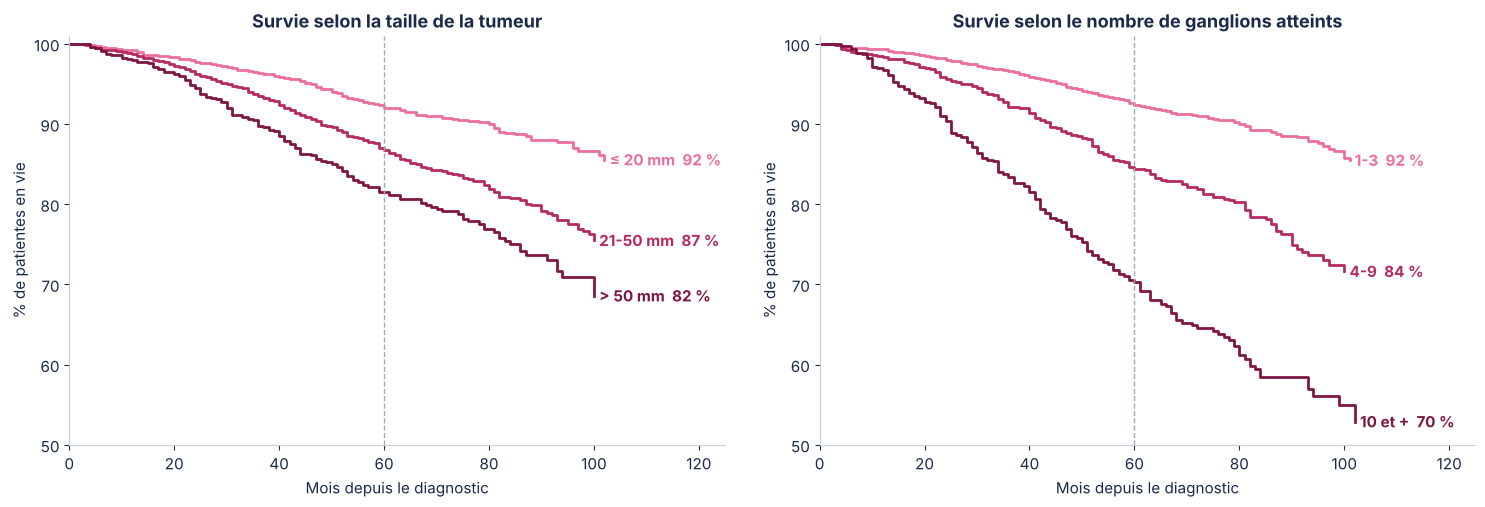

Log-rank Taille : χ² = 69.7, p = 6.7e-16


,patientes,survie à 5 ans (%)
Taille,,
≤ 20 mm,1619,91.9
21-50 mm,1824,86.8
> 50 mm,580,81.6


Log-rank Ganglions : χ² = 275.5, p < 1e-16


,patientes,survie à 5 ans (%)
Ganglions,,
1-3,2681,92.4
4-9,881,84.4
10 et +,461,70.2


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
courbes("Taille", ["≤ 20 mm", "21-50 mm", "> 50 mm"], [RAMPE[1], RAMPE[3], RAMPE[4]], "Survie selon la taille de la tumeur", axes[0])
courbes("Ganglions", ["1-3", "4-9", "10 et +"], [RAMPE[1], RAMPE[3], RAMPE[4]], "Survie selon le nombre de ganglions atteints", axes[1])
plt.tight_layout(); plt.show()
display(tableau_survie("Taille", ["≤ 20 mm", "21-50 mm", "> 50 mm"]))
display(tableau_survie("Ganglions", ["1-3", "4-9", "10 et +"]))

- Tumeur **≤ 20 mm : 92 %** de survie à 5 ans, contre **82 %** au-delà de 50 mm.
- **1 à 3 ganglions** atteints : **92 %**, contre **70 %** à partir de 10 ganglions.

L'atteinte ganglionnaire est le facteur le plus discriminant : c'est l'argument central d'une campagne de dépistage.

## 8. Biologie de la tumeur : récepteurs hormonaux et grade

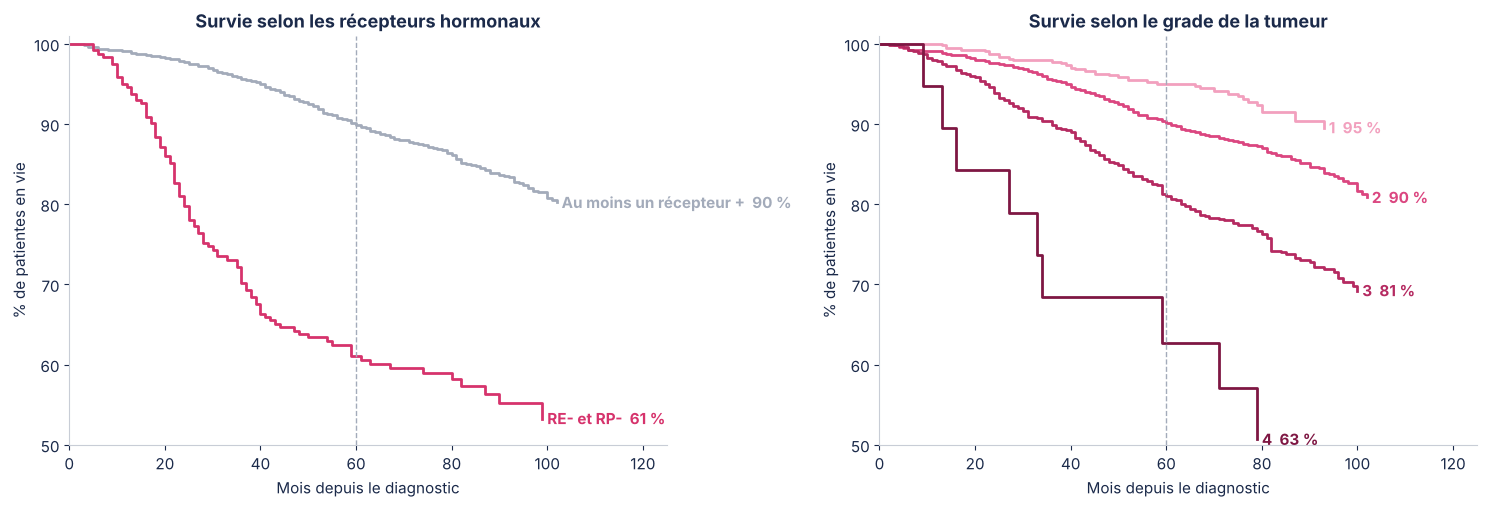

Log-rank Hormones : χ² = 186.2, p < 1e-16


,patientes,survie à 5 ans (%)
Hormones,,
Au moins un récepteur +,3781,89.8
RE- et RP-,242,61.1


Log-rank Grade : χ² = 112.2, p < 1e-16


,patientes,survie à 5 ans (%)
Grade,,
1,543,95.0
2,2350,90.1
3,1111,81.0
4,19,62.7


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
courbes("Hormones", ["Au moins un récepteur +", "RE- et RP-"], [GRIS, ROSE], "Survie selon les récepteurs hormonaux", axes[0])
courbes("Grade", ["1", "2", "3", "4"], [RAMPE[0], RAMPE[2], RAMPE[3], RAMPE[4]], "Survie selon le grade de la tumeur", axes[1])
plt.tight_layout(); plt.show()
display(tableau_survie("Hormones", ["Au moins un récepteur +", "RE- et RP-"]))
display(tableau_survie("Grade", ["1", "2", "3", "4"]))

Les tumeurs **sans récepteurs hormonaux** (RE- et RP-, 6 % des cas) ont une survie à 5 ans de **61 %**, contre **90 %** pour les autres. Ces tumeurs ne répondent pas à l'hormonothérapie : l'accès au test des récepteurs et à un traitement adapté est un enjeu de plaidoyer.

## 9. Facteurs démographiques et sociaux

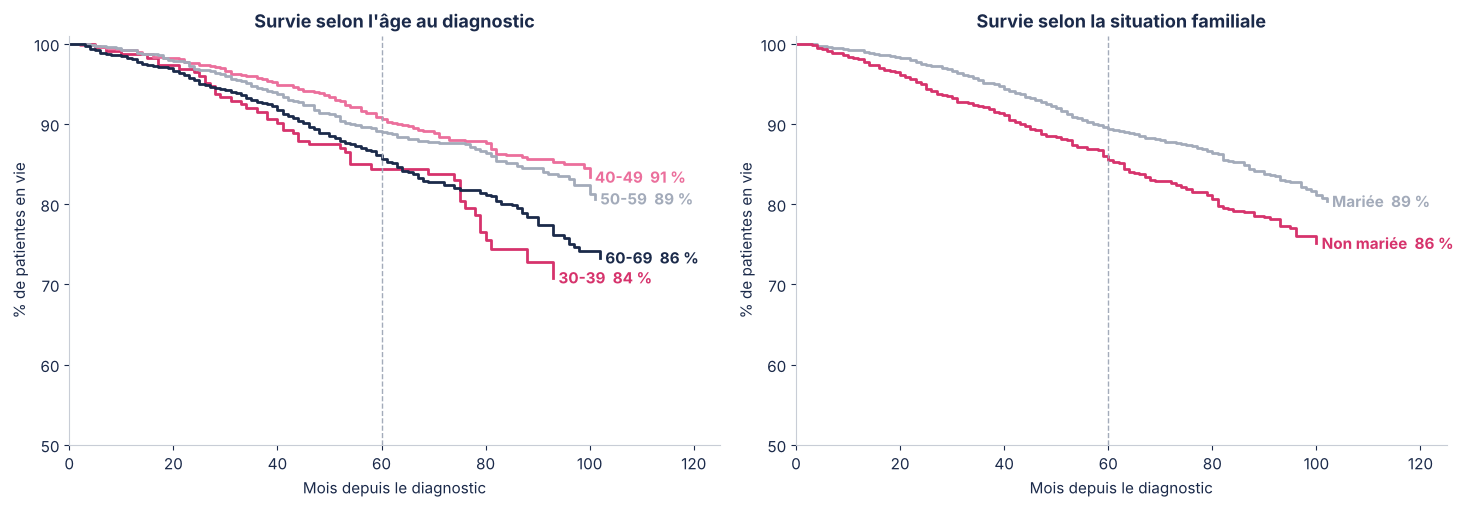

Log-rank Âge : χ² = 31.5, p = 6.7e-07


,patientes,survie à 5 ans (%)
Âge,,
30-39,230,84.4
40-49,1124,90.6
50-59,1390,89.0
60-69,1279,85.6


Log-rank Situation : χ² = 18.7, p = 1.5e-05


,patientes,survie à 5 ans (%)
Situation,,
Mariée,2642,89.4
Non mariée,1381,85.6


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
courbes("Âge", ["30-39", "40-49", "50-59", "60-69"], [ROSE, RAMPE[1], GRIS, NAVY], "Survie selon l'âge au diagnostic", axes[0])
courbes("Situation", ["Mariée", "Non mariée"], [GRIS, ROSE], "Survie selon la situation familiale", axes[1])
plt.tight_layout(); plt.show()
display(tableau_survie("Âge", ["30-39", "40-49", "50-59", "60-69"]))
display(tableau_survie("Situation", ["Mariée", "Non mariée"]))

- Les **plus jeunes (30-39 ans)** et les **plus âgées (60-69 ans)** ont un pronostic moins bon que les 40-59 ans.
- Les femmes **non mariées** (célibataires, divorcées, veuves, séparées) ont une mortalité plus élevée : 18,7 % contre 13,6 %. Le soutien social et l'accompagnement pendant le parcours de soins peuvent jouer un rôle.

## 10. Modèle de Cox : quels facteurs pèsent vraiment, toutes choses égales par ailleurs ?

Les facteurs sont liés entre eux (une tumeur plus grosse a plus souvent des ganglions atteints, etc.). Le modèle de Cox estime l'effet propre de chaque facteur. Un **hazard ratio (HR) de 2** signifie un risque de décès deux fois plus élevé à chaque instant, par rapport à la catégorie de référence.

In [14]:
formule = ("mois ~ C(Âge, Treatment('40-49')) + C(Race, Treatment('White')) + C(Situation, Treatment('Mariée'))"
           " + C(Q('T Stage'), Treatment('T1')) + C(Q('N Stage'), Treatment('N1')) + C(Grade, Treatment('1'))"
           " + C(Q('Estrogen Status'), Treatment('Positive')) + C(Q('Progesterone Status'), Treatment('Positive'))")
cox = PHReg.from_formula(formule, df, status=df["deces"].values, ties="efron").fit()

libelles = {"Âge, Treatment('40-49'))[T.30-39]": "Âge 30-39 ans (vs 40-49)",
            "Âge, Treatment('40-49'))[T.50-59]": "Âge 50-59 ans (vs 40-49)",
            "Âge, Treatment('40-49'))[T.60-69]": "Âge 60-69 ans (vs 40-49)",
            "Race, Treatment('White'))[T.Black]": "Afro-américaine (vs blanche)",
            "Race, Treatment('White'))[T.Other]": "Autre origine (vs blanche)",
            "Situation, Treatment('Mariée'))[T.Non mariée]": "Non mariée (vs mariée)",
            "T Stage'), Treatment('T1'))[T.T2]": "Tumeur T2 (vs T1)",
            "T Stage'), Treatment('T1'))[T.T3]": "Tumeur T3 (vs T1)",
            "T Stage'), Treatment('T1'))[T.T4]": "Tumeur T4 (vs T1)",
            "N Stage'), Treatment('N1'))[T.N2]": "Ganglions N2 (vs N1)",
            "N Stage'), Treatment('N1'))[T.N3]": "Ganglions N3 (vs N1)",
            "Grade, Treatment('1'))[T.2]": "Grade 2 (vs 1)",
            "Grade, Treatment('1'))[T.3]": "Grade 3 (vs 1)",
            "Grade, Treatment('1'))[T.4]": "Grade 4 (vs 1)",
            "Estrogen Status'), Treatment('Positive'))[T.Negative]": "Récepteurs œstrogènes négatifs",
            "Progesterone Status'), Treatment('Positive'))[T.Negative]": "Récepteurs progestérone négatifs"}
def libelle(nom):
    for k, v in libelles.items():
        if nom.endswith(k):
            return v
    return nom

ci = np.exp(cox.conf_int())
hr = pd.DataFrame({"HR": np.exp(cox.params), "IC 95 % bas": ci[:, 0], "IC 95 % haut": ci[:, 1], "p-value": cox.pvalues},
                  index=[libelle(n) for n in cox.model.exog_names]).round(3)
hr

,HR,IC 95 % bas,IC 95 % haut,p-value
Âge 30-39 ans (vs 40-49),1.490,1.068,2.079,0.019
Âge 50-59 ans (vs 40-49),1.106,0.885,1.382,0.376
Âge 60-69 ans (vs 40-49),1.756,1.419,2.173,0.000
Afro-américaine (vs blanche),1.431,1.113,1.840,0.005
Autre origine (vs blanche),0.683,0.480,0.973,0.035
Non mariée (vs mariée),1.221,1.036,1.438,0.017
Tumeur T2 (vs T1),1.440,1.182,1.755,0.000
Tumeur T3 (vs T1),1.602,1.246,2.059,0.000
Tumeur T4 (vs T1),2.529,1.765,3.625,0.000
Ganglions N2 (vs N1),1.809,1.483,2.205,0.000


C-index = 0.741


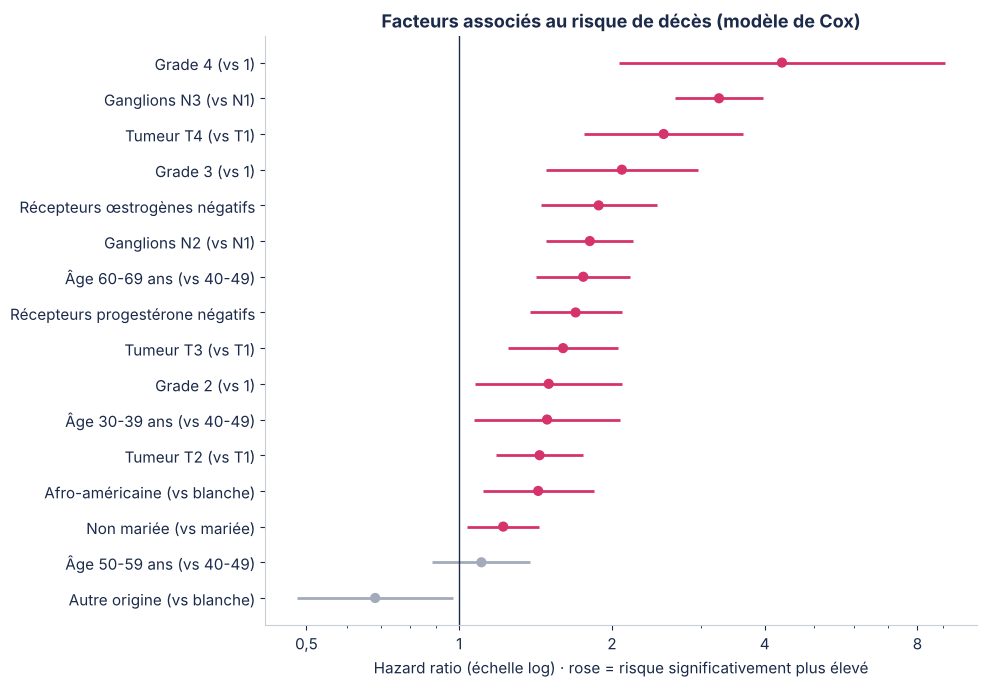

In [15]:
# Indice de concordance de Harrell : capacité du modèle à classer les patientes selon leur risque
lp = cox.model.exog @ cox.params
t, e = df["mois"].values, df["deces"].values
conc = paires = 0
for i in np.where(e == 1)[0]:
    m = t > t[i]
    paires += m.sum()
    conc += (lp[m] < lp[i]).sum() + 0.5 * (lp[m] == lp[i]).sum()
print(f"C-index = {conc / paires:.3f}")

h = hr.sort_values("HR")
fig, ax = plt.subplots(figsize=(10, 7))
couleurs = [ROSE if (lo > 1) else GRIS for lo in h["IC 95 % bas"]]
ax.hlines(range(len(h)), h["IC 95 % bas"], h["IC 95 % haut"], color=couleurs, lw=2)
ax.scatter(h["HR"], range(len(h)), color=couleurs, s=40, zorder=3)
ax.axvline(1, color=NAVY, lw=1)
ax.set_yticks(range(len(h))); ax.set_yticklabels(h.index)
ax.set_xscale("log"); ax.set_xticks([0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0,5", "1", "2", "4", "8"])
ax.set_xlabel("Hazard ratio (échelle log) · rose = risque significativement plus élevé")
ax.set_title("Facteurs associés au risque de décès (modèle de Cox)")
plt.tight_layout(); plt.show()

**Lecture :**
- À caractéristiques égales, des **ganglions N3** multiplient le risque de décès par **3,3**, une tumeur **T4** par **2,5** et un **grade 4** par **4,3**.
- Des **récepteurs hormonaux négatifs** augmentent le risque (HR 1,9 pour les œstrogènes, 1,7 pour la progestérone).
- Le fait d'être **non mariée** reste associé à un risque plus élevé (HR 1,22), même à stade et biologie identiques.
- Le modèle classe correctement les patientes selon leur risque dans **74 %** des paires comparables (C-index 0,74).

Il s'agit d'**associations**, pas de liens de cause à effet.

## 11. Synthèse et recommandations pour l'ONG

| Constat | Ce que les données montrent | Action pour l'ONG |
|---|---|---|
| Le stade au diagnostic détermine la survie | 94 % de survie à 5 ans au stade IIA, 69 % au stade IIIC | Faire du **diagnostic précoce** le message central d'Octobre Rose : autopalpation, examen clinique, mammographie |
| L'atteinte ganglionnaire est le facteur clé | HR 3,3 pour N3 ; 70 % de survie à partir de 10 ganglions | Mesurer et suivre la **part de diagnostics précoces** comme indicateur d'impact |
| Les tumeurs sans récepteurs hormonaux sont plus graves | 61 % de survie à 5 ans | **Plaidoyer** pour l'accès aux tests des récepteurs et aux traitements adaptés |
| Jeunes femmes et femmes de 60 ans et + plus exposées | HR 1,5 (30-39 ans) et 1,8 (60-69 ans) | **Cibler** aussi les moins de 40 ans, souvent hors des campagnes de dépistage |
| L'isolement social pèse sur le pronostic | HR 1,22 pour les femmes non mariées | **Accompagner** : pair-aidance, transport, suivi du parcours de soins |

## 12. Limites

- **Données américaines (2006-2010)** : les ordres de grandeur ne sont pas transposables tels quels au Sénégal, où l'accès au dépistage et aux traitements est différent.
- **Population sélectionnée** : uniquement des femmes de 30 à 69 ans avec atteinte ganglionnaire (stades II-III). Le bénéfice d'un diagnostic encore plus précoce (stade I, sans ganglion) n'est pas mesuré ici et serait probablement plus important.
- **Associations, pas causalités** : la situation familiale ou l'origine sont des marqueurs d'autres facteurs (accès aux soins, revenus) non disponibles dans le jeu de données.
- **Qualité** : 7 tumeurs T3 de taille incohérente, signalées mais conservées.